# Tests de validation MSUC

Ce notebook entraine la politique SDDP sur une instance puis la simule. On choisit l'instance,
l'horizon, le nombre de scenarios, la formulation (3-bin ou intervalle) et les reglages de `train`
(nombre d'iterations, ecart d'optimalite du MIP racine), puis on regarde la trajectoire de la borne
inferieure, le cout de la politique simulee et la repartition du temps de calcul.

Les verifications rigoureuses (borne <= optimum exact <= politique, equivalence des formulations
3-bin et intervalle, Prop. 3) sont dans `examples/toy_convergence.jl` et `examples/compare_formulations.jl`.

A executer depuis la racine du depot (le kernel Julia active automatiquement ce projet).

## 1. Installation des dependances (une seule fois)

Installe les paquets listes dans `Project.toml` (JuMP, Gurobi.jl, CSV, DataFrames, NCDatasets, ...). 
Necessite une licence Gurobi valide sur la machine.

In [1]:
import Pkg
Pkg.activate(@__DIR__)  # active ce projet, quel que soit le kernel Julia choisi
Pkg.instantiate()

  Activating project at `~/Documents/MSUC`


In [2]:
using MSUC, Gurobi, Printf, Random

GRB_ENV = Gurobi.Env()
optimizer = () -> Gurobi.Optimizer(GRB_ENV)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05


#2 (generic function with 1 method)

In [15]:
INSTANCE    = "Data/T-Ramp/50_0_1_w.nc4"  # chemin vers le fichier .nc4
T           = 24                           # horizon (nombre de pas de temps)
S           = 5                            # nombre de scenarios (support de l'innovation ARMA)
FORCE       = 1.0                          # amplitude de l'alea (0.0 = deterministe)
ITERATIONS  = 60                          # nombre d'iterations SDDP
MIP_GAP     = 1e-3                         # ecart d'optimalite du MIP racine : 1e-2 = 1 %, 1e-3 = 0.1 %, nothing = defaut du solveur (1e-4)
PASSES_PER_MIP = 3                         # passes avant/arriere (LP) par resolution du MIP racine : 1 = usuel, 5 ou 10 = plus de coupes entre deux MIP ; ITERATIONS compte alors des cycles
PRINT_LEVEL = 1                            # 0 = silencieux, 1 = log complet de MSUC.train

# :threebin  -> formulation 3-bin  (Sect. 2 de l'article, coupes (12))
# :extended  -> formulation intervalle (Sect. 3 de l'article, coupes (41))
METHOD = :extended

:extended

In [11]:
FORMULATIONS = Dict(
    :threebin => (MSUC.subproblem_builder_UC_def,     MSUC.SDDPFormulation,     "3-bin"),
    :extended => (MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation, "intervalle"),
)
builder, method, label = FORMULATIONS[METHOD]

instance = MSUC.parse_nc4(INSTANCE, optimizer, T; S = S)
@printf("instance %s : %d unites, %d intervalles, T = %d, S = %d, methode = %s\n",
        basename(INSTANCE), instance.N,
        sum(length(u.intervals) for u in instance.Thermalunits), T, S, label)

instance 50_0_1_w.nc4 : 50 unites, 10314 intervalles, T = 24, S = 5, methode = intervalle


In [ ]:
model = MSUC.PolicyGraph(
    builder, instance, FORCE, MSUC.Graph(T + 1), method;
    lower_bound = 0.0, optimizer = optimizer,
)

MSUC.train(model; iteration_limit = ITERATIONS, mip_gap = MIP_GAP,
            passes_per_mip = PASSES_PER_MIP, print_level = PRINT_LEVEL)

-------------------------------------------------------------------
         MSUC.jl (c) Oscar Dowson and contributors, 2017-25
-------------------------------------------------------------------
problem
  nodes           : 25
  state variables : 52
  scenarios       : 5.96046e+16
  existing cuts   : false
subproblem structure
  VariableRef                             : [359, 14069]
  AffExpr in MOI.EqualTo{Float64}         : [3, 4972]
  AffExpr in MOI.GreaterThan{Float64}     : [1, 51]
  AffExpr in MOI.LessThan{Float64}        : [200, 4800]
  VariableRef in MOI.EqualTo{Float64}     : [1, 1]
  VariableRef in MOI.GreaterThan{Float64} : [52, 10364]
  VariableRef in MOI.LessThan{Float64}    : [50, 50]
  VariableRef in MOI.Parameter{Float64}   : [250, 250]
  VariableRef in MOI.ZeroOne              : [3650, 3650]
numerical stability report
  matrix range     [1e-01, 7e+03]
  objective range  [1e+00, 4e+03]
  bounds range     [1e+02, 3e+02]
  rhs range        [1e+00, 7e+03]
-----------------

### Resultats : trajectoire de la borne et cout de la politique simulee

it   1   borne = 125664.80
it   2   borne = 1588435.73
it   3   borne = 1682426.95
it   4   borne = 1740132.50
it   5   borne = 1815292.71
it   6   borne = 7542862.68
it   7   borne = 7545868.07
it   8   borne = 7558726.56
it   9   borne = 7588386.78
it  10   borne = 7590625.07
it  11   borne = 7919837.37
it  12   borne = 7934197.06
it  13   borne = 7937650.03
it  14   borne = 7945532.87
it  15   borne = 7948357.54
it  16   borne = 7963193.62
it  17   borne = 7994755.24
it  18   borne = 7995717.28
it  19   borne = 8004671.04
it  20   borne = 8004918.39
it  21   borne = 8004918.39
it  22   borne = 8005155.53
it  23   borne = 8031503.61
it  24   borne = 8034407.82
it  25   borne = 8035621.41
it  26   borne = 8038830.88
it  27   borne = 8038830.88
it  28   borne = 8039066.66
it  29   borne = 8039066.66
it  30   borne = 8041689.61
it  31   borne = 8041822.43
it  32   borne = 8042280.60
it  33   borne = 8042280.60
it  34   borne = 8042736.88
it  35   borne = 8045072.18


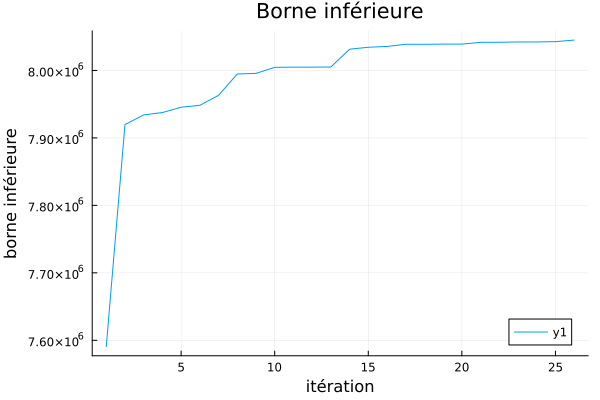

In [ ]:
using Plots
log = model.most_recent_training_results.log
for l in log
    @printf("it %3d   borne = %.2f\n", l.iteration, l.bound)
end
plot([l.bound for l in log if l.iteration >= 10], title = "Borne inférieure", xlabel = "itération", ylabel = "borne inférieure")

In [14]:
t_sim = @elapsed sim = MSUC.simulate(model)
@printf("\ncout de la politique simulee = %.2f  (%d chemins, exhaustif = %s, %.1f s)\n",
        sim.cost, sim.npaths, sim.exhaustive, t_sim)
@printf("borne finale = %.2f  ->  encadrement relatif = %.2e\n",
        log[end].bound, 100*(sim.cost - log[end].bound) / abs(log[end].bound))


cout de la politique simulee = 8624138.67  (1000 chemins, exhaustif = false, 8.4 s)
borne finale = 8045072.18  ->  encadrement relatif = 7.20e+00


### Temps de calcul par poste

Chronometres de `train` : racine (MIP), passe avant, passe arriere (resolution des LP, calcul des
coefficients des coupes, ajout des coupes) et mise a jour du planning.

In [8]:
MSUC.TimerOutputs.print_timer(stdout, model.timer_output; compact = true)

─────────────────────────────────────────────────────────────────────
                                          Time          Allocations  
                                    ───────────────   ───────────────
          Total measured:                21.2s            3.56GiB    

Section                     ncalls     time    %tot     alloc    %tot
─────────────────────────────────────────────────────────────────────
solve_first_stage_problem        5    4.50s   56.6%    261MiB   16.6%
backward_pass                   15    1.88s   23.6%   1.02GiB   66.2%
  compute_coefficients         350    1.07s   13.5%    852MiB   54.2%
  solve_subproblem           1.75k    668ms    8.4%    166MiB   10.6%
    get_dual_solution        1.75k    392ms    4.9%    106MiB    6.8%
  add_cut                      350    137ms    1.7%   22.1MiB    1.4%
forward_pass                    15    978ms   12.3%    204MiB   13.0%
  solve_subproblem             360    896ms   11.3%    195MiB   12.4%
  sample_scenario  

### Temps du MIP racine par iteration

Le probleme racine est un MIP resolu a chaque iteration : c'est en general le poste dominant de `train`.
Son temps croit avec le nombre de coupes accumulees ; l'option `MIP_GAP` (cellule des parametres) permet de l'accelerer.

MIP racine : 3.6 s au total, soit 45 % du temps d'entrainement (8.0 s)


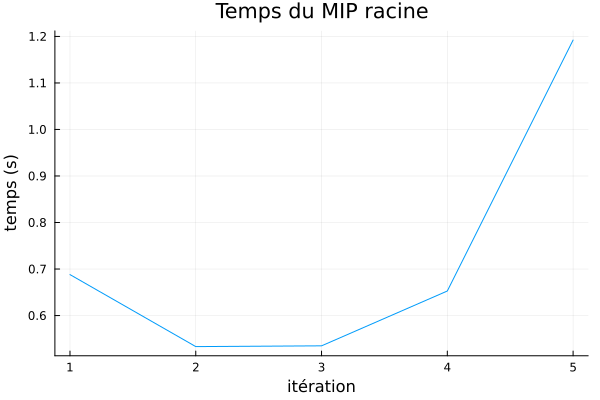

In [9]:
using Plots
t_mip = model[1].computation_time[1:length(log)]   # une resolution du MIP racine par iteration
@printf("MIP racine : %.1f s au total, soit %.0f %% du temps d'entrainement (%.1f s)\n",
        sum(t_mip), 100 * sum(t_mip) / log[end].time, log[end].time)
plot(t_mip, title = "Temps du MIP racine", xlabel = "itération", ylabel = "temps (s)", legend = false)